In [1]:
# ============================================================
# CELL 1: Environment
# ============================================================
import sys, sklearn, pandas as pd, numpy as np
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.10.11
scikit-learn: 1.7.2
pandas: 2.3.3
numpy: 2.2.6


In [2]:
# ============================================================
# CELL 2: Build multilingual stopwords file
# ============================================================
import json
from pathlib import Path

STOPWORDS_PATH = Path("multilingual_stopwords.json")

HINDI_STOPWORDS = {
    "का","के","की","को","में","से","पर","और","या","एक","यह","वह","ये","वे",
    "है","हैं","था","थी","थे","हो","होता","होती","होते","कर","करना","किया","कि",
    "जो","तो","भी","नहीं","न","ही","तक","लिए","साथ","बाद","पहले","अपना","अपनी",
    "अपने","इस","उस","इन","उन","कुछ","सब","कोई","कैसे","क्या","क्यों","कब",
    "कहाँ","जब","तब","अब","मैं","हम","तुम","आप","वो","मुझे","हमें","तुम्हें",
    "आपको","रहा","रही","रहे","गया","गई","गए","दिया","दी","दिए","लिया","ली",
    "लिए","बहुत","कम","ज़्यादा","अधिक","हर","सिर्फ",
}

HINGLISH_STOPWORDS = {
    "hai","hain","haan","nahi","nahin","na","ki","ka","ke","ko","ne","me","mein",
    "se","hi","jo","to","ta","te","ti","par","pe","ra","ri","ro","naa","ji","jee",
    "ha","kya","kyun","kyu","kaise","kab","kahan","kahin","kisi","kuch","aisa",
    "waise","ab","tab","jab","abhi","phir","fir","baad","pehle","saath","sath",
    "liye","hota","hoti","hote","hua","hui","hue","gaya","gayi","gaye","jaa","ja",
    "raha","rahi","rahe","kar","karke","karna","karni","karne","diya","di","de",
    "do","le","li","lo","tha","thi","the","hu","hoon","hey","hello","hm","hmm",
    "ok","okay","bas","bhi","bohot","bahut","acha","accha","achha","bhai","bro",
    "yaar","matlab","sirf","wala","wali","wale","koi","koyi","ek","teen","char",
    "paisa","time","log","baat","cheez","karo","karte",
}

TELUGU_EXTRA = {
    "మరియు","ఈ","ఆ","ఒక","కు","లో","తో","యొక్క","కోసం","అది","ఇది",
    "వారు","అయిన","గా","నుండి","పై","కి","చేసిన","అన్ని","ఉన్న","లేదు",
    "కాదు","మాత్రమే",
}

def try_load_library_stopwords():
    sw = {}
    try:
        import advertools as adv
        for lang in ["nepali","tamil","telugu"]:
            if lang in adv.stopwords:
                sw[lang] = set(adv.stopwords[lang])
        print(f"advertools loaded: {list(sw.keys())}")
    except Exception as e:
        print(f"advertools unavailable ({e}); using fallback lists.")
    try:
        from nltk.corpus import stopwords as nltk_sw
        if "nepali" not in sw:
            sw["nepali"] = set(nltk_sw.words("nepali"))
            print("NLTK loaded nepali")
    except Exception:
        pass
    return sw

lib_sw = try_load_library_stopwords()
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOPWORDS_DICT = {
    "hindi":    sorted(HINDI_STOPWORDS),
    "hinglish": sorted(HINGLISH_STOPWORDS),
    "nepali":   sorted(lib_sw.get("nepali", set())),
    "tamil":    sorted(lib_sw.get("tamil", set())),
    "telugu":   sorted(set(lib_sw.get("telugu", set())) | TELUGU_EXTRA),
    "english":  sorted(ENGLISH_STOP_WORDS),
}

with open(STOPWORDS_PATH, "w", encoding="utf-8") as f:
    json.dump(STOPWORDS_DICT, f, ensure_ascii=False, indent=2)

print(f"\nStopwords file saved: {STOPWORDS_PATH}")
for lang, words in STOPWORDS_DICT.items():
    print(f"  {lang:10s}: {len(words)} words")

advertools unavailable (No module named 'advertools'); using fallback lists.
NLTK loaded nepali

Stopwords file saved: multilingual_stopwords.json
  hindi     : 82 words
  hinglish  : 115 words
  nepali    : 254 words
  tamil     : 0 words
  telugu    : 23 words
  english   : 318 words


In [3]:
# ============================================================
# CELL 3: Load stopwords + multilingual tokenizer
# ============================================================
import json, re
from pathlib import Path

with open(Path("multilingual_stopwords.json"), "r", encoding="utf-8") as f:
    STOPWORDS_DICT = json.load(f)

ALL_STOPWORDS = set()
for words in STOPWORDS_DICT.values():
    ALL_STOPWORDS.update(w.lower() for w in words)
print(f"Total unique stopwords: {len(ALL_STOPWORDS)}")

TOKEN_PATTERN = re.compile(
    r"[A-Za-z\u0900-\u097F\u0B80-\u0BFF\u0C00-\u0C7F]+", re.UNICODE
)

def tokenize_and_filter(text):
    if not isinstance(text, str):
        return []
    toks = TOKEN_PATTERN.findall(text.lower())
    return [t for t in toks
            if t not in ALL_STOPWORDS and not (len(t) == 1 and t.isascii())]

print(tokenize_and_filter("यह एक अच्छा जवाब है, but Hinglish bhi hai"))

Total unique stopwords: 772
['अच्छा', 'जवाब', 'hinglish']


In [4]:
# ============================================================
# CELL 4: Load raw files and merge
# ============================================================
import pandas as pd, numpy as np
from pathlib import Path

BASE_DIR = Path(r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark")
DATA_PATH       = BASE_DIR / "data/annotations/final/final_annotations.csv"
RESPONSES_PATH  = BASE_DIR / "data/annotations/working/responses.json"
REFERENCES_PATH = BASE_DIR / "data/annotations/working/references.json"

responses_df   = pd.read_json(RESPONSES_PATH)
references_df  = pd.read_json(REFERENCES_PATH)
annotations_df = pd.read_csv(DATA_PATH, low_memory=False)

for df in [responses_df, references_df, annotations_df]:
    if "question_id" in df.columns:
        df["question_id"] = df["question_id"].astype("string").str.strip()
    if "language" in df.columns:
        df["language"] = df["language"].astype("string").str.strip().str.upper()
    if "model_name" in df.columns:
        df["model_name"] = df["model_name"].astype("string").str.strip()

LANGUAGE_ALIASES = {"HIEN": "HI-EN", "HI_EN": "HI-EN", "HINGLISH": "HI-EN"}
for df in [responses_df, annotations_df]:
    df["language"] = df["language"].replace(LANGUAGE_ALIASES)

assert references_df["question_id"].is_unique
KEYS = ["question_id", "language", "model_name"]
assert not responses_df.duplicated(KEYS).any()
assert not annotations_df.duplicated(KEYS).any()

refs_slim = references_df.drop(
    columns=["fact_id","domain","difficulty","source_url"], errors="ignore"
)

merged = responses_df.merge(
    refs_slim, on="question_id", how="left",
    validate="many_to_one", suffixes=("_resp", "_ref"),
)
merged = merged.merge(
    annotations_df[KEYS + ["response_id","correctness_label","hallucination_types",
                           "severity","confidence","judge_model"]],
    on=KEYS, how="left", validate="one_to_one",
)

print("Merged rows:", len(merged))
print(merged["correctness_label"].value_counts(dropna=False))

Merged rows: 64800
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64


In [5]:
# ============================================================
# CELL 5: Clean + label encode
# ============================================================
from sklearn.preprocessing import LabelEncoder

for col in ["question", "ground_truth", "response"]:
    merged[col] = merged[col].fillna("").astype(str).str.strip()

merged = merged[
    (merged["question"] != "") &
    (merged["ground_truth"] != "") &
    (merged["response"] != "")
].copy()

LABEL_FIX = {
    "correct":"Correct","incorrect":"Incorrect",
    "partially correct":"Partially Correct","partial":"Partially Correct",
    "uncertain":"Uncertain",
}
merged["correctness_label"] = (
    merged["correctness_label"].astype("string").str.strip().replace(LABEL_FIX)
)
VALID = {"Correct","Partially Correct","Incorrect","Uncertain"}
bad = set(merged["correctness_label"].dropna()) - VALID
assert not bad, f"Unexpected labels: {bad}"
merged = merged.dropna(subset=["correctness_label"]).copy()

le = LabelEncoder()
merged["label"] = le.fit_transform(merged["correctness_label"])
LABELS = list(le.classes_)
NUM_LABELS = len(LABELS)
print("Labels:", LABELS)
print("Rows after cleaning:", len(merged))

Labels: ['Correct', 'Incorrect', 'Partially Correct']
Rows after cleaning: 64800


In [6]:
# ============================================================
# CELL 6: StratifiedGroupKFold split
# ============================================================
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

SEED = 42

def pick_fact_id_col(df):
    for c in ["fact_id","fact_id_resp","fact_id_ref",
              "fact_id_response","fact_id_reference"]:
        if c in df.columns:
            return c
    return None

fact_col = pick_fact_id_col(merged)
if fact_col is None:
    merged["split_group"] = "QUESTION_" + merged["question_id"].astype(str)
else:
    ids = merged[fact_col].astype(str).str.strip()
    invalid = ids.isin(["", "nan", "None", "<NA>"]) | merged[fact_col].isna()
    merged["split_group"] = np.where(
        ~invalid, "FACT_" + ids,
        "QUESTION_" + merged["question_id"].astype(str),
    )

sgkf_test = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = list(sgkf_test.split(merged["question"], merged["label"],
                             groups=merged["split_group"]))
test_pos = np.concatenate([folds[i][1] for i in range(3)])
remaining_idx = np.setdiff1d(np.arange(len(merged)), test_pos)

remaining = merged.iloc[remaining_idx].reset_index(drop=True)
test_df   = merged.iloc[test_pos].reset_index(drop=True).copy()

sgkf_dev = StratifiedGroupKFold(n_splits=17, shuffle=True, random_state=SEED + 1)
dev_folds = list(sgkf_dev.split(remaining["question"], remaining["label"],
                                groups=remaining["split_group"]))
dev_pos = np.concatenate([dev_folds[i][1] for i in range(3)])

dev_df   = remaining.iloc[dev_pos].reset_index(drop=True).copy()
train_df = remaining.drop(index=remaining.index[dev_pos]).reset_index(drop=True).copy()

assert set(train_df["split_group"]).isdisjoint(set(dev_df["split_group"]))
assert set(train_df["split_group"]).isdisjoint(set(test_df["split_group"]))
assert set(dev_df["split_group"]).isdisjoint(set(test_df["split_group"]))

total = len(merged)
print(f"Train: {len(train_df):>6,} ({len(train_df)/total*100:.2f}%)")
print(f"Dev:   {len(dev_df):>6,} ({len(dev_df)/total*100:.2f}%)")
print(f"Test:  {len(test_df):>6,} ({len(test_df)/total*100:.2f}%)")
print("Leakage check: PASSED")

for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts(normalize=True).mul(100).round(2)
    print(f"  {name:5s}: {dict(vc)}")

Train: 45,360 (70.00%)
Dev:    9,720 (15.00%)
Test:   9,720 (15.00%)
Leakage check: PASSED
  Train: {'Correct': np.float64(61.29), 'Incorrect': np.float64(19.98), 'Partially Correct': np.float64(18.73)}
  Dev  : {'Correct': np.float64(59.43), 'Incorrect': np.float64(21.07), 'Partially Correct': np.float64(19.5)}
  Test : {'Correct': np.float64(60.51), 'Incorrect': np.float64(20.39), 'Partially Correct': np.float64(19.09)}


In [7]:
# ============================================================
# CELL 7: Lexical overlap features
# ============================================================
import re, numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

_TOKEN_RE = re.compile(r"[A-Za-z\u0900-\u097F\u0B80-\u0BFF\u0C00-\u0C7F]+", re.UNICODE)

def _toks(s):
    return set(_TOKEN_RE.findall(str(s).lower()))

def _nums(s):
    return set(re.findall(r"\d+(?:\.\d+)?", str(s)))

NEGATIONS = {"no","not","never","none","cannot","can't","don't","doesn't",
             "isn't","won't","नहीं","न","मत","నహి","ఇల్ల"}

class OverlapFeatures(BaseEstimator, TransformerMixin):
    """Handcrafted features: response vs ground-truth overlap signals."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        rows = []
        for _, r in X.iterrows():
            resp = str(r.get("response", ""))
            gt   = str(r.get("ground_truth", ""))
            q    = str(r.get("question", ""))
            rt, gt_t = _toks(resp), _toks(gt)
            rn, gn   = _nums(resp), _nums(gt)
            inter    = len(rt & gt_t)
            union    = len(rt | gt_t) or 1
            rows.append([
                len(rt), len(gt_t),
                len(resp) / (len(gt) + 1),
                inter / union,
                inter / (len(gt_t) + 1),
                inter / (len(rt) + 1),
                len(rn), len(gn),
                len(rn & gn) / (len(gn) + 1),
                len(rn - gn),
                sum(w in rt for w in NEGATIONS) -
                sum(w in gt_t for w in NEGATIONS),
                len(rt & _toks(q)) / (len(_toks(q)) + 1),
            ])
        return np.asarray(rows, dtype=np.float32)

OVERLAP_COLS = ["resp_len","gt_len","len_ratio","jaccard",
                "gt_recall","gt_precision","resp_nums","gt_nums",
                "num_overlap","num_halluc","neg_diff","q_echo"]

In [8]:
# ============================================================
# CELL 8: Pickle-safe column selectors + vectorizer factories
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler

class ColumnSelector:
    """Pick a single column from a DataFrame -> list[str]."""
    def __init__(self, column: str):
        self.column = column
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.column].astype(str).tolist()

class MultiColumnSelector:
    """Return a DataFrame with selected columns."""
    def __init__(self, columns):
        self.columns = list(columns)
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.columns].copy()

def make_word_vec(field: str) -> Pipeline:
    return Pipeline([
        ("get", ColumnSelector(field)),
        ("tfidf", TfidfVectorizer(
            analyzer="word",
            token_pattern=r"[A-Za-z\u0900-\u097F\u0B80-\u0BFF\u0C00-\u0C7F]+",
            lowercase=True, sublinear_tf=True,
            ngram_range=(1, 2), min_df=2, max_df=0.95,
            max_features=80_000,
            stop_words=list(ALL_STOPWORDS),
        )),
    ])

def make_char_vec(field: str) -> Pipeline:
    return Pipeline([
        ("get", ColumnSelector(field)),
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 5),
            sublinear_tf=True, min_df=2, max_features=60_000,
            lowercase=True,
        )),
    ])

def make_overlap_pipe() -> Pipeline:
    return Pipeline([
        ("get", MultiColumnSelector(["question","ground_truth","response"])),
        ("ovl", OverlapFeatures()),
        ("sc",  MaxAbsScaler()),
    ])

TRAINING FEATURE UNION + LINEAR SVM
Training time: 17.88 seconds
Training samples: 45360
Classes: [0 1 2]

Calibrating Linear SVM probabilities...
Calibration time: 2.31 seconds
ROC-AUC unavailable: Target scores need to be probabilities for multiclass roc_auc, i.e. they should sum up to 1.0 over classes

DEV - LINEAR SVM EVALUATION
Accuracy                 : 0.7168
Macro Precision          : 0.6540
Weighted Precision       : 0.7098
Macro Recall             : 0.6361
Weighted Recall          : 0.7168
Macro F1                 : 0.6441
Weighted F1              : 0.7124
Balanced Accuracy        : 0.6361
Cohen's Kappa            : 0.4859
MCC                      : 0.4868
ROC-AUC (Macro)          : nan
Log Loss                 : 0.6777

CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.7949    0.8411    0.8173      5777
           1     0.6237    0.5601    0.5902      2048
   

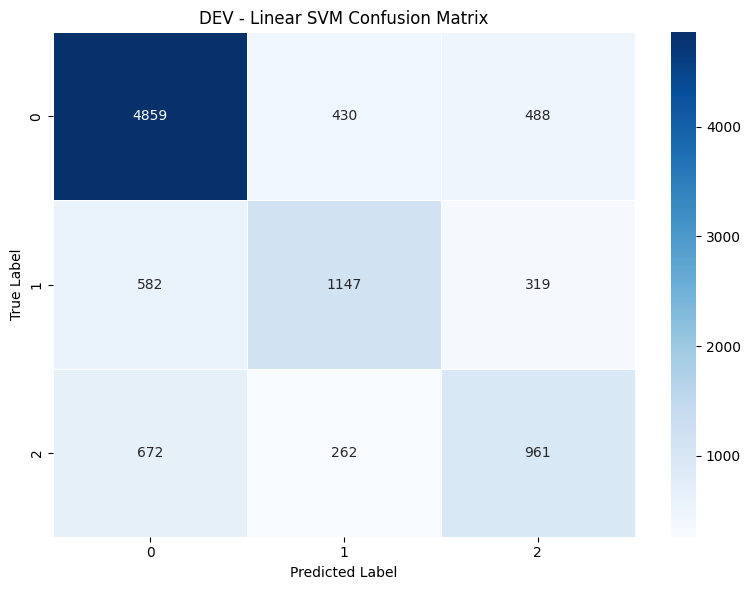

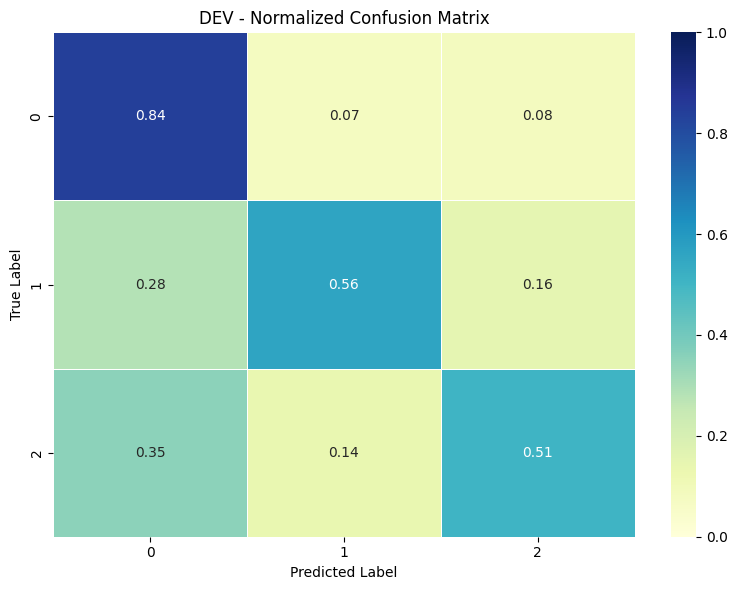

ROC-AUC unavailable: Target scores need to be probabilities for multiclass roc_auc, i.e. they should sum up to 1.0 over classes

TEST - LINEAR SVM EVALUATION
Accuracy                 : 0.7248
Macro Precision          : 0.6541
Weighted Precision       : 0.7183
Macro Recall             : 0.6388
Weighted Recall          : 0.7248
Macro F1                 : 0.6458
Weighted F1              : 0.7209
Balanced Accuracy        : 0.6388
Cohen's Kappa            : 0.4942
MCC                      : 0.4949
ROC-AUC (Macro)          : nan
Log Loss                 : 0.6647

CLASSIFICATION REPORT
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.8103    0.8487    0.8290      5882
           1     0.6153    0.5641    0.5886      1982
           2     0.5367    0.5038    0.5197      1856

    accuracy                         0.7248      9720
   macro avg     0.6541    0.6388    0.6458      9720
weighted avg     

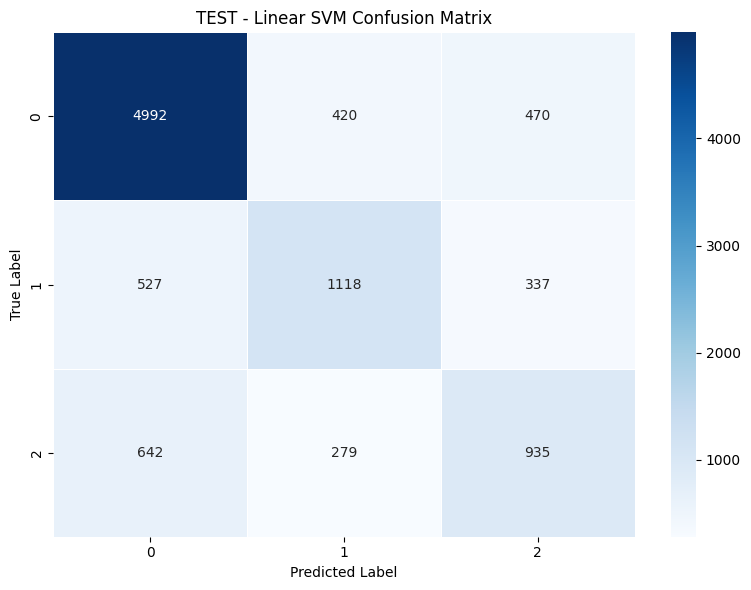

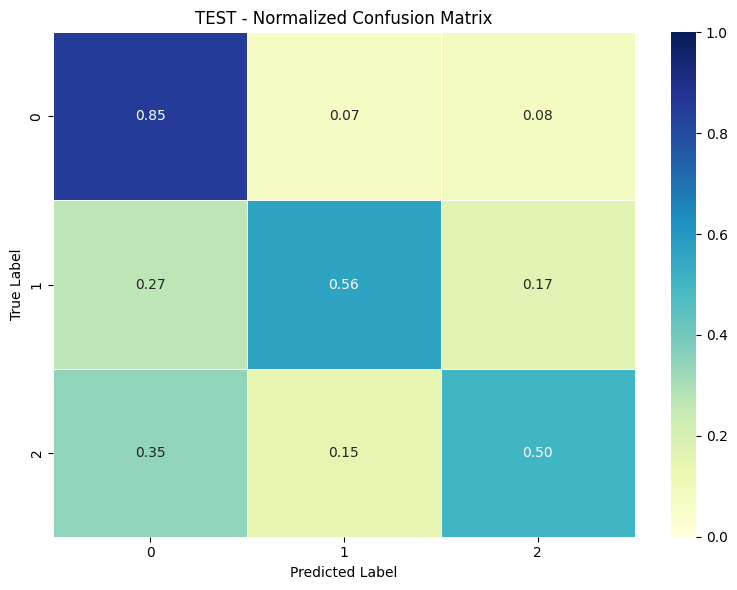


LINEAR SVM: DEV VS TEST COMPARISON


,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,Cohen's Kappa,MCC,ROC-AUC (Macro),Log Loss
Dataset,,,,,,,,,,,,,
DEV,Linear SVM,0.7168,0.6540,0.7098,0.6361,0.7168,0.6441,0.7124,0.6361,0.4859,0.4868,NaN,0.6777
TEST,Linear SVM,0.7248,0.6541,0.7183,0.6388,0.7248,0.6458,0.7209,0.6388,0.4942,0.4949,NaN,0.6647


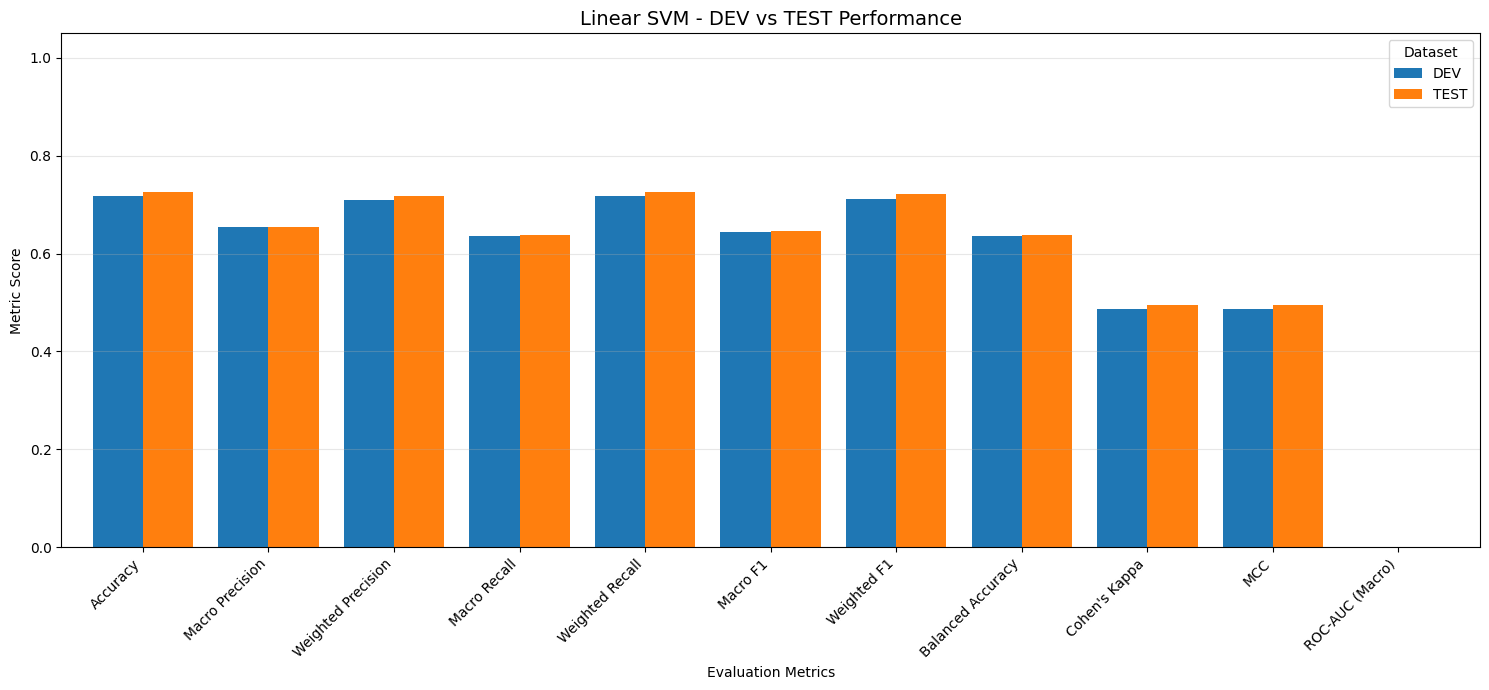

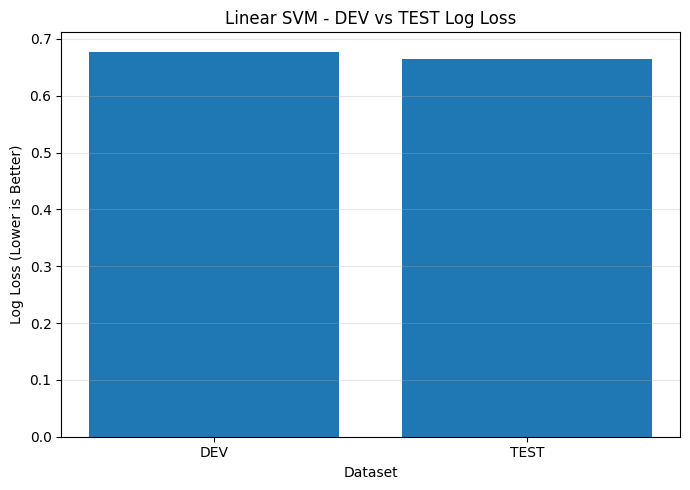

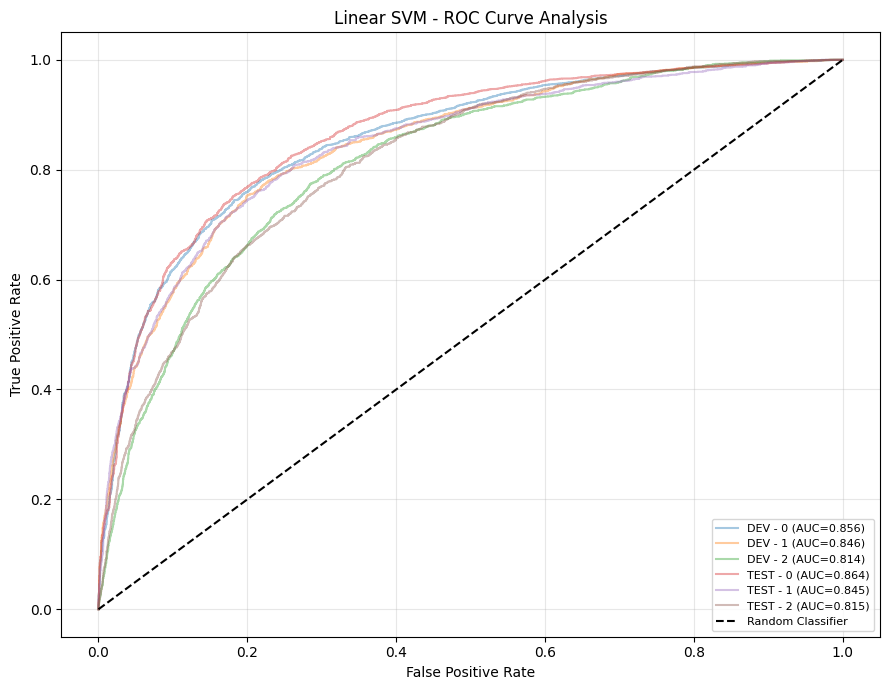


LINEAR SVM EVALUATION COMPLETED
Training time: 17.88 seconds
Calibration time: 2.31 seconds
Saved: linear_svm_evaluation_comparison.csv


In [9]:

# ============================================================
# CELL 9: FEATURE UNION + LINEAR SVM
# COMPREHENSIVE MULTICLASS EVALUATION
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Feature engineering
# ------------------------------------------------------------

features = FeatureUnion([
    ("q_word",  make_word_vec("question")),
    ("gt_word", make_word_vec("ground_truth")),
    ("r_word",  make_word_vec("response")),
    ("r_char", make_char_vec("response")),
    ("raw",     make_overlap_pipe()),
], n_jobs=1)

# ------------------------------------------------------------
# 2. Linear SVM classifier
# ------------------------------------------------------------

svc = LinearSVC(
    C=0.5,
    class_weight="balanced",
    dual="auto",
    max_iter=5000,
    random_state=42
)

# Base SVM pipeline
svm_pipe = Pipeline([
    ("feats", features),
    ("clf", svc)
])

# ------------------------------------------------------------
# 3. Train Linear SVM
# ------------------------------------------------------------

print("=" * 70)
print("TRAINING FEATURE UNION + LINEAR SVM")
print("=" * 70)

t0 = time.time()

svm_pipe.fit(
    train_df,
    train_df["label"]
)

svm_train_time = time.time() - t0

print(f"Training time: {svm_train_time:.2f} seconds")
print(f"Training samples: {len(train_df)}")
print(f"Classes: {svm_pipe.classes_}")

# ------------------------------------------------------------
# 4. Probability calibration
# ------------------------------------------------------------

# Calibrate the already-fitted SVM using the DEV dataset.
# This avoids fitting the feature extractor again.
# DEV must not be used for final performance reporting
# without accounting for calibration/model selection.

print("\nCalibrating Linear SVM probabilities...")

t0 = time.time()

svm_calibrated = CalibratedClassifierCV(
    estimator=svm_pipe,
    method="sigmoid",
    cv="prefit"
)

svm_calibrated.fit(
    dev_df,
    dev_df["label"]
)

calibration_time = time.time() - t0

print(f"Calibration time: {calibration_time:.2f} seconds")

# ------------------------------------------------------------
# 5. Comprehensive evaluation function
# ------------------------------------------------------------

def evaluate_svm(name, df, base_model, calibrated_model):

    y_true = df["label"].values

    # Predicted labels from original Linear SVM
    y_pred = base_model.predict(df)

    # Raw SVM decision scores for ranking-based ROC-AUC
    decision_scores = base_model.decision_function(df)

    # Calibrated probabilities for log loss
    y_prob = calibrated_model.predict_proba(df)

    classes = base_model.classes_
    n_classes = len(classes)

    # --------------------------------------------------------
    # Classification metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_precision = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_recall = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    # --------------------------------------------------------
    # Agreement metrics
    # --------------------------------------------------------

    kappa = cohen_kappa_score(
        y_true, y_pred
    )

    mcc = matthews_corrcoef(
        y_true, y_pred
    )

    # --------------------------------------------------------
    # Probability-based Log Loss
    # --------------------------------------------------------

    ll = log_loss(
        y_true,
        y_prob,
        labels=classes
    )

    # --------------------------------------------------------
    # ROC-AUC using SVM decision scores
    # --------------------------------------------------------

    try:

        if n_classes == 2:

            roc_auc = roc_auc_score(
                y_true,
                decision_scores
            )

        else:

            roc_auc = roc_auc_score(
                y_true,
                decision_scores,
                labels=classes,
                multi_class="ovr",
                average="macro"
            )

    except ValueError as e:

        print(f"ROC-AUC unavailable: {e}")
        roc_auc = np.nan

    # --------------------------------------------------------
    # Store all metrics
    # --------------------------------------------------------

    metrics = {
        "Model": "Linear SVM",
        "Dataset": name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Weighted Precision": weighted_precision,
        "Macro Recall": macro_recall,
        "Weighted Recall": weighted_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Balanced Accuracy": balanced_acc,
        "Cohen's Kappa": kappa,
        "MCC": mcc,
        "ROC-AUC (Macro)": roc_auc,
        "Log Loss": ll
    }

    # --------------------------------------------------------
    # Print evaluation results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print(f"{name} - LINEAR SVM EVALUATION")
    print("=" * 70)

    for metric, value in metrics.items():

        if metric not in ["Model", "Dataset"]:

            print(f"{metric:<25}: {value:.4f}")

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nCLASSIFICATION REPORT")
    print("-" * 70)

    print(classification_report(
        y_true,
        y_pred,
        labels=classes,
        target_names=[str(c) for c in classes],
        digits=4,
        zero_division=0
    ))

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5
    )

    plt.title(f"{name} - Linear SVM Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Normalized confusion matrix
    # --------------------------------------------------------

    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes,
        normalize="true"
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        xticklabels=classes,
        yticklabels=classes,
        vmin=0,
        vmax=1,
        linewidths=0.5
    )

    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    return metrics, y_true, y_pred, decision_scores, y_prob


# ------------------------------------------------------------
# 6. Evaluate DEV and TEST
# ------------------------------------------------------------

svm_dev_results = evaluate_svm(
    "DEV",
    dev_df,
    svm_pipe,
    svm_calibrated
)

svm_test_results = evaluate_svm(
    "TEST",
    test_df,
    svm_pipe,
    svm_calibrated
)

# ------------------------------------------------------------
# 7. Consolidated DEV vs TEST comparison
# ------------------------------------------------------------

svm_comparison_df = pd.DataFrame([
    svm_dev_results[0],
    svm_test_results[0]
])

svm_comparison_df = svm_comparison_df.set_index("Dataset")

print("\n" + "=" * 75)
print("LINEAR SVM: DEV VS TEST COMPARISON")
print("=" * 75)

display(svm_comparison_df.round(4))

# ------------------------------------------------------------
# 8. Metric comparison visualization
# ------------------------------------------------------------

plot_metrics = [
    "Accuracy",
    "Macro Precision",
    "Weighted Precision",
    "Macro Recall",
    "Weighted Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy",
    "Cohen's Kappa",
    "MCC",
    "ROC-AUC (Macro)"
]

svm_comparison_df[plot_metrics].T.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title(
    "Linear SVM - DEV vs TEST Performance",
    fontsize=14
)

plt.ylabel("Metric Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Log Loss comparison
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    svm_comparison_df.index,
    svm_comparison_df["Log Loss"]
)

plt.title("Linear SVM - DEV vs TEST Log Loss")
plt.ylabel("Log Loss (Lower is Better)")
plt.xlabel("Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. ROC Curve analysis
# ------------------------------------------------------------

classes = svm_pipe.classes_
n_classes = len(classes)

svm_datasets = {
    "DEV": (svm_dev_results[1], svm_dev_results[3]),
    "TEST": (svm_test_results[1], svm_test_results[3])
}

plt.figure(figsize=(9, 7))

if n_classes == 2:

    for dataset_name, (y_true, scores) in svm_datasets.items():

        fpr, tpr, _ = roc_curve(
            y_true,
            scores,
            pos_label=classes[1]
        )

        roc_value = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{dataset_name} (AUC={roc_value:.4f})"
        )

else:

    for dataset_name, (y_true, scores) in svm_datasets.items():

        y_bin = label_binarize(
            y_true,
            classes=classes
        )

        if scores.ndim == 1:
            continue

        for i, cls in enumerate(classes):

            if len(np.unique(y_bin[:, i])) < 2:
                continue

            fpr, tpr, _ = roc_curve(
                y_bin[:, i],
                scores[:, i]
            )

            roc_value = auc(fpr, tpr)

            plt.plot(
                fpr,
                tpr,
                alpha=0.4,
                label=f"{dataset_name} - {cls} (AUC={roc_value:.3f})"
            )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random Classifier"
)

plt.title("Linear SVM - ROC Curve Analysis")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Save evaluation results
# ------------------------------------------------------------

svm_comparison_df.to_csv(
    "linear_svm_evaluation_comparison.csv"
)

print("\n" + "=" * 70)
print("LINEAR SVM EVALUATION COMPLETED")
print("=" * 70)

print(f"Training time: {svm_train_time:.2f} seconds")
print(f"Calibration time: {calibration_time:.2f} seconds")

print(
    "Saved: linear_svm_evaluation_comparison.csv"
)

In [10]:
# ============================================================
# CELL 10: Tune C, calibrate probabilities, soft-voting ensemble
# ============================================================
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd

def build_svm(C=0.5, calibrated=False):
    base = LinearSVC(C=C, class_weight="balanced", dual="auto", max_iter=5000)
    clf = CalibratedClassifierCV(base, cv=3, method="sigmoid") if calibrated else base
    return Pipeline([("feats", features), ("clf", clf)])

# ---- 1) Tune C on dev (raw LinearSVC, no calibration; cheaper) ----
best = (None, -1.0)
for C in [0.1, 0.25, 0.5, 1.0, 2.0, 4.0]:
    m = build_svm(C=C, calibrated=False)
    m.fit(train_df, train_df["label"])
    f1m = f1_score(dev_df["label"], m.predict(dev_df), average="macro")
    print(f"C={C:<5} dev macro-F1={f1m:.4f}")
    if f1m > best[1]:
        best = (C, f1m)

C_best, dev_best = best
print(f"\nBest C={C_best}  (dev macro-F1={dev_best:.4f})")

# ---- 2) Fit on train+dev with calibrated SVM ----
train_dev = pd.concat([train_df, dev_df], ignore_index=True)

svm_final  = build_svm(C=C_best, calibrated=True).fit(train_dev, train_dev["label"])
lr_final   = Pipeline([
    ("feats", features),
    ("clf",   LogisticRegression(C=4.0, max_iter=3000, solver="liblinear",
                                 class_weight="balanced")),
]).fit(train_dev, train_dev["label"])

ens = VotingClassifier(
    estimators=[("svm", svm_final), ("lr", lr_final)],
    voting="soft", n_jobs=-1,
).fit(train_dev, train_dev["label"])

# ---- 3) Evaluate everything on test ----
for name, m in [("SVM (calibrated)", svm_final),
                ("LR  (baseline)",   lr_final),
                ("ENSEMBLE",         ens)]:
    yp = m.predict(test_df)
    print(f"\n{name:18s} test acc={accuracy_score(test_df['label'], yp):.4f} "
          f"macro-F1={f1_score(test_df['label'], yp, average='macro'):.4f}")
    print(classification_report(test_df["label"], yp,
                                target_names=LABELS, digits=4))

C=0.1   dev macro-F1=0.6582
C=0.25  dev macro-F1=0.6530
C=0.5   dev macro-F1=0.6441
C=1.0   dev macro-F1=0.6364
C=2.0   dev macro-F1=0.6309
C=4.0   dev macro-F1=0.6256

Best C=0.1  (dev macro-F1=0.6582)

SVM (calibrated)   test acc=0.7420 macro-F1=0.6491
                   precision    recall  f1-score   support

          Correct     0.7792    0.9096    0.8393      5882
        Incorrect     0.6782    0.5328    0.5968      1982
Partially Correct     0.6214    0.4343    0.5113      1856

         accuracy                         0.7420      9720
        macro avg     0.6930    0.6255    0.6491      9720
     weighted avg     0.7285    0.7420    0.7272      9720


LR  (baseline)     test acc=0.7437 macro-F1=0.6690
                   precision    recall  f1-score   support

          Correct     0.8161    0.8655    0.8401      5882
        Incorrect     0.6478    0.5782    0.6110      1982
Partially Correct     0.5791    0.5345    0.5559      1856

         accuracy                      

In [11]:
# ============================================================
# CELL 11: Save + slice analysis + error inspection
# ============================================================
import joblib, json, sklearn, sys

joblib.dump(ens, "tfidf_svm_hallucination.joblib", compress=3)
with open("label_classes.json", "w") as f:
    json.dump(LABELS, f)
with open("model_meta.json", "w") as f:
    json.dump({"sklearn": sklearn.__version__,
               "python": sys.version.split()[0],
               "model": "TFIDF+LinearSVC ensemble"}, f)
print("Saved model + metadata")

# reload sanity check
ens_loaded = joblib.load("tfidf_svm_hallucination.joblib")
assert (ens_loaded.predict(test_df) == ens.predict(test_df)).all()
print("Reload check: OK")

test_pred = ens.predict(test_df)
test_eval = test_df.copy()
test_eval["pred_label"] = test_pred
test_eval["pred_name"]  = [LABELS[i] for i in test_pred]

for grp in ["language", "model_name"]:
    print(f"\n=== Accuracy by {grp} ===")
    print(test_eval.groupby(grp).apply(
        lambda d: (d["label"] == d["pred_label"]).mean()
    ).round(4))

print("\n=== Error analysis (top 5 misclassified) ===")
bad = test_eval[test_eval["label"] != test_eval["pred_label"]]
for _, r in bad.head(5).iterrows():
    print(f"\n[{LABELS[r['label']]} -> {r['pred_name']}] ({r['language']})")
    print("Q :", r["question"][:120])
    print("GT:", r["ground_truth"][:120])
    print("R :", r["response"][:120])

Saved model + metadata
Reload check: OK

=== Accuracy by language ===
language
EN       0.7565
HI       0.7675
HI-EN    0.7444
NE       0.7374
TA       0.7426
TE       0.7342
dtype: float64

=== Accuracy by model_name ===
model_name
Claude Sonnet 5.5      0.7556
DeepSeek-V4.1-Flash    0.7488
GLM-5.3 Flash          0.7765
GPT-5.6 Luna           0.7414
Gemini 3               0.7346
Qwen 3.7               0.7259
dtype: float64

=== Error analysis (top 5 misclassified) ===

[Correct -> Partially Correct] (EN)
Q : How were GATT decisions made compared to the WTO's dispute settlement system?
GT: consensus, dispute settlement
R : GATT decisions generally relied on consensus and diplomatic negotiation, whereas the WTO has a more formal, rules-based 

[Incorrect -> Correct] (EN)
Q : What is another name for the African Plate?
GT: Nubian Plate
R : The African Plate

[Incorrect -> Partially Correct] (EN)
Q : What distinguishes the Sargasso Sea from seas that are enclosed by coastlines?
GT: The Sa